Setup Kaggle and Download Dataset

In [ ]:
import os

# Set your Kaggle API Token as an environment variable
os.environ['KAGGLE_CONFIG_DIR'] = '/content'

# Create the .kaggle directory if it doesn't exist
!mkdir -p ~/.kaggle

# Verify it works
!kaggle datasets list

ref                                                              title                                                    size  lastUpdated                 downloadCount  voteCount  usabilityRating  
---------------------------------------------------------------  -------------------------------------------------  ----------  --------------------------  -------------  ---------  ---------------  
dmitriigluzdov/casmi26-pubchem-popularity-prior                  CASMI26 PubChem Popularity Prior                   1286771429  2026-10-05 02:40:35.677000           4606         42                1  
srisyra02/zomato-market-analysis                                 Restaurant Market Analysis: Ratings, Prices            444049  2026-09-17 17:02:06.437000           4670        100                1  
dreaddevelopment/raptor-knee-maxspan                             Knee MRI - Max-Span Dense Corpus                    271659195  2026-08-22 20:14:47.093000           1640         50           0.8125  


In [ ]:
!kaggle datasets download -d salader/dogsvscats

Dataset URL: https://www.kaggle.com/datasets/salader/dogsvscats
License(s): unknown
dogsvscats.zip: Skipping, found more recently modified local copy (use --force to force download)


In [ ]:
!unzip -q dogsvscats.zip -d ./dataset

replace ./dataset/catsvsdogs/test/cats/cat.10.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: 

In [ ]:
import os

print("Extracted folders/files:")
print(os.listdir('./dataset'))

Extracted folders/files:
['test', 'catsvsdogs', 'train']


Importing the Libraries

In [ ]:
import tensorflow as tf
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense,Conv2D,MaxPooling2D,Flatten,BatchNormalization,Dropout
from keras.layers import RandomFlip, RandomRotation, RandomZoom
import matplotlib.pyplot as plt
import cv2

In [ ]:
#generators- data divided into batch and in ram one batch work done and in next another batch
#so generator are used to process large amount of data

In [ ]:
# Load the training dataset
train_ds = keras.utils.image_dataset_from_directory(
    directory='/content/dataset/train',
    labels='inferred',
    label_mode='int', #cats-0 and dog-1
    batch_size=32,
    image_size=(256, 256)
)
# Load the validation dataset
validation_ds = keras.utils.image_dataset_from_directory(
    directory='/content/dataset/test',
    labels='inferred',
    label_mode='int',
    batch_size=32,
    image_size=(256, 256)
)

Found 20000 files belonging to 2 classes.
Found 5000 files belonging to 2 classes.


Data Preprocessing and Normalization

In [ ]:
#Normalize to make all values betn 0 and 1
#Because neural networks generally train more easily when the input values are small and consistently scaled.
def process(image, label):
    image = tf.cast(image / 255., tf.float32)
    return image, label
#tf.cast() converts the data into the speicific type.
#we changed the image but we dont want to chose label so we return both

train_ds = train_ds.map(process)
validation_ds = validation_ds.map(process)

#We create a function process which gets image and label
#in image we divide by 255 and again return both image and label
#map function takes one image and label and return to function


CNN MODEL ARCHITECTURE

In [ ]:
model = Sequential()

# Data Augmentation
model.add(RandomFlip("horizontal"))
model.add(RandomRotation(0.1))
model.add(RandomZoom(0.1))

# 1st Convolutional Block
model.add(Conv2D(32, kernel_size=(3, 3), padding='valid', activation='relu', input_shape=(256, 256, 3)))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2, 2), strides=2, padding='valid'))

# 2nd Convolutional Block
model.add(Conv2D(64, kernel_size=(3, 3), padding='valid', activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2, 2), strides=2, padding='valid'))

# 3rd Convolutional Block
model.add(Conv2D(128, kernel_size=(3, 3), padding='valid', activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2, 2), strides=2, padding='valid'))

# Flattening and Fully Connected Layers
model.add(Flatten())

model.add(Dense(128, activation='relu'))
model.add(Dropout(0.1))

model.add(Dense(64, activation='relu'))
model.add(Dropout(0.1))

# Output Layer for Binary Classification
model.add(Dense(1, activation='sigmoid'))

model.summary()


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_1 (RandomFlip)      │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_1               │ ?                      │   0 (unbuilt) │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_1 (RandomZoom)      │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ ?                      │   0 (unbuilt) │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ ?                      │   0 (unbuilt) │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ ?                      │   0 (unbuilt) │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Model Compilation and Training

In [ ]:
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Execute training across 10 epochs
history = model.fit(train_ds, epochs=10, validation_data=validation_ds)

Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 76s 99ms/step - accuracy: 0.5465 - loss: 1.3078 - val_accuracy: 0.5244 - val_loss: 0.7166
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 57s 91ms/step - accuracy: 0.5860 - loss: 0.6674 - val_accuracy: 0.6298 - val_loss: 0.6197
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 58s 94ms/step - accuracy: 0.6314 - loss: 0.6375 - val_accuracy: 0.6858 - val_loss: 0.6512
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 57s 91ms/step - accuracy: 0.6944 - loss: 0.5698 - val_accuracy: 0.6560 - val_loss: 0.6014
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 63s 101ms/step - accuracy: 0.7566 - loss: 0.4745 - val_accuracy: 0.7806 - val_loss: 0.4606
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 60s 96ms/step - accuracy: 0.7983 - loss: 0.4152 - val_accuracy: 0.7452 - val_loss: 0.4837
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 62s 99ms/step - accuracy: 0.8214 - loss: 0.3662 - val_accuracy: 0.7504 - val_loss: 0.6066
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 59s 95ms/step - accuracy: 0.8474 - loss: 0.3201 -

Model Evaluation

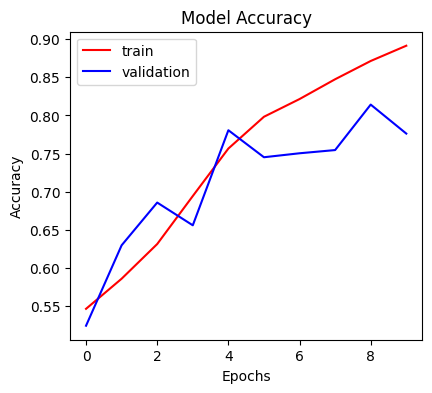

In [ ]:
# Plot Accuracy
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], color='red', label='train')
plt.plot(history.history['val_accuracy'], color='blue', label='validation')
plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

## epcoh increase train accuracy increase but validation fluctuates and there is a lot of gap betn them so overfitting

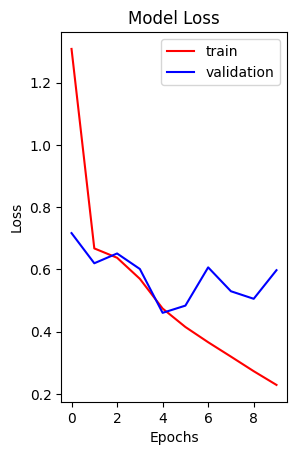

In [ ]:
# Plot Loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], color='red', label='train')
plt.plot(history.history['val_loss'], color='blue', label='validation')
plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [ ]:
#ways to reduce overfitting

#Add more data
#Data Augumentation
#L1/L2 Regularization
#Dropout
#Batch Normalization
#Reduce Complexity


Prediction

In [ ]:
# Replace path with your actual test image path (e.g., 'cat.jpg' or 'dog.jpg')
image_path = '/content/cat.jpeg'

if os.path.exists(image_path):
    test_img = cv2.imread(image_path)
    # Convert BGR (OpenCV default) to RGB for correct matplotlib plotting
    test_img_rgb = cv2.cvtColor(test_img, cv2.COLOR_BGR2RGB)
    plt.imshow(test_img_rgb)
    plt.axis('off')
    plt.show()

    # Preprocess the image to fit model expectations
    test_img_resized = cv2.resize(test_img, (256, 256))
    test_input = test_img_resized.reshape((1, 256, 256, 3))

    # Scale image pixels if the training pipeline scales them
    test_input = test_input / 255.0

    # Prediction
    prediction = model.predict(test_input)
    print(f"Raw Prediction Value: {prediction[0][0]}")

    if prediction[0][0] < 0.5:
        print("Prediction: It's a CAT!")
    else:
        print("Prediction: It's a DOG!")
else:
    print(f"Image not found at {image_path}. Please check your path.")

Image not found at /content/cat.jpeg. Please check your path.


In [ ]:
model.save("dog_cat_model.keras")

In [ ]:
# Dataset → Loads the cat and dog images with their labels.
# Normalization → Converts pixel values from 0–255 to 0–1.
# Data Augmentation → Creates slightly changed versions of training images to reduce overfitting.
# Conv2D → Detects visual features like edges, shapes, and textures.
# BatchNormalization → Keeps the layer values stable so training becomes smoother.
# MaxPooling → Shrinks the image features while keeping the important information.
# Conv2D (again) → Learns more complex features from the previous features.
# BatchNormalization → Stabilizes those newly learned features.
# MaxPooling → Reduces their size again.
# Conv2D (again) → Learns even higher-level features like parts of ears, eyes, fur, etc.
# BatchNormalization → Stabilizes these features.
# MaxPooling → Reduces the feature-map size again.
# Flatten → Converts all the 2D feature maps into one long 1D list.
# Dense(128) → Combines the learned features to make a decision.
# Dropout → Randomly ignores some neurons during training to reduce overfitting.
# Dense(64) → Further processes the features for classification.
# Dropout → Again ignores some neurons to help prevent overfitting.
# Dense(1, sigmoid) → Produces one value between 0–1 representing the cat/dog prediction.
# Prediction → < 0.5 = CAT, ≥ 0.5 = DOG.